# Review saved genetic winners

Load a winner archive without running Stage 1, Stage 2, or a new GA. The original seed, mouthpiece, tuning and constraints are reconstructed from the archive, not from today's configuration files. No winners are written or changed.

Run all cells with the project environment. Select an archive and winner below. Scores are recomputed with the current optimizer; dense acoustic checks separately compare the original seed, the GA-adapted seed and the selected winner. Predicted tuning and Q are passive acoustic-model results, not playing-test validation.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from tin_whistle_openwind.geometry import DEFAULT_DATA_DIR, MouthpieceGeometry, TaperedBoreGeometry, UndercutTonehole, WhistleGeometryFactory
from tin_whistle_openwind.genetic_optimizer import GeneticAlgorithmConfig, GeneticGeometryOptimizer, GeometryDNA, normalized_pitch_costs, normalized_q_rewards, GEOMETRY_RESOLUTION_M
from tin_whistle_openwind.genetic_winners import WinnerArchive
from tin_whistle_openwind.keys import WhistleKeyConfig
from tin_whistle_openwind.optimizer import OpenWInDToneholeModel, ToneholeLayout, MIN_ADJACENT_HOLE_SPACINGS_M
from tin_whistle_openwind.resonances import resonance_peak_rows
from tin_whistle_openwind.tuning import TuningProfile, SECOND_REGISTER_FINGERINGS, generate_key_frequencies

ARCHIVE_DIRECTORY = DEFAULT_DATA_DIR / 'ga-winners'
archives = sorted(ARCHIVE_DIRECTORY.glob('*.json'))
if not archives:
    raise FileNotFoundError(f'No saved winners found in {ARCHIVE_DIRECTORY}. Complete a GA run first.')
archive_rows = []
for path in archives:
    payload = json.loads(path.read_text(encoding='utf-8'))
    archive_rows.append({'Archive': path.name, 'Key': payload['context']['key']['name'], 'Winners': len(payload['winners']), 'Stored best cost': payload['winners'][0]['rank'][1] if payload['winners'] else np.nan})
display(pd.DataFrame(archive_rows).rename_axis('Archive index'))

,Archive,Key,Winners,Stored best cost
Archive index,,,,
0,982822b1953fc350ab79c32d430feec9fd7e1e69522f50...,Soprano High D,10,402.310840
1,c7c4a2879acc4adf892dde32e5bd8578d8a37b0d26f40f...,Soprano High D,10,23.859809
2,ce9c3f6663a39635379aeb61b79795068eeb7edee556da...,Soprano High D,10,779.038080
3,f4087f4467b509c0d8df1f60166147093f8d1ba8a2c6c2...,Soprano High D,10,395.132240


## Select and reconstruct

`ARCHIVE_INDEX` chooses an entry above; `WINNER_INDEX` chooses its stored rank (zero is best). Saved costs are historical. Revisions 1-3 are rescored with normalized 60/40 pitch costs and Q disabled. Revision 4 uses the saved Q reward parameters and hole geometry schema. Legacy outward-flare semantics are retained; old stored and recomputed costs need not match. Archives are never changed.

In [2]:
ARCHIVE_INDEX = 3
WINNER_INDEX = 0
DENSE_POINTS = 4801

archive_path = archives[ARCHIVE_INDEX]
payload = json.loads(archive_path.read_text(encoding='utf-8'))
context = payload['context']
if context['scoring_revision'] not in (1, 2, 3, 4) or not context['geometry_and_scoring']['root_relative_q']:
    raise ValueError('This review requires scoring revision 1-4 with root_relative_q enabled.')
archive = WinnerArchive(archive_path.parent, context)
if archive.path != archive_path:
    raise ValueError('Archive filename does not match its saved context fingerprint.')
saved = archive._read()  # Read-only validation; avoids creating a lock or changing the archive.
if not saved:
    raise ValueError('The selected archive contains no winners.')
seed_bore = TaperedBoreGeometry(**context['bore'])
seed_layout = ToneholeLayout([UndercutTonehole(**hole) for hole in context['holes']])
mouthpiece = MouthpieceGeometry(**context['mouthpiece']) if context['mouthpiece'] is not None else None
key = WhistleKeyConfig(**context['key'])
tuning = TuningProfile(**context['tuning'])
config = GeneticAlgorithmConfig(**context['geometry_and_scoring'], workers=1, winner_directory=None)
optimizer = GeneticGeometryOptimizer(key, tuning, seed_bore, seed_layout, temperature=context['temperature'], mouthpiece=mouthpiece, config=config)
notes = tuple(context['notes'])
vectors = [np.asarray(genome, dtype=float) for genome, _ in saved]
for vector in vectors:
    if not np.allclose(vector, optimizer.codec.repair(vector), atol=1e-12, rtol=0):
        raise ValueError('A saved genome no longer satisfies the current geometry rules.')
scores = [optimizer._score(vector, notes, retune=False) for vector in vectors]
leaderboard = pd.DataFrame([{'Stored rank': i, 'Stored cost': saved[i][1][1], 'Recomputed cost': score.cost, 'Pitch cost': score.pitch_cost, 'Q reward': score.q_reward, 'Cost difference': score.cost - saved[i][1][1], 'Length (mm)': score.vector[0] * 1000, 'Lower root (cents)': score.errors.get('Degree_1'), 'Upper root (cents)': score.errors.get('Octave_Degree_1'), 'Minimum resolved Q': min((q for q in score.q_factors.values() if q is not None), default=np.nan), 'Unresolved Q': sum(q is None for q in score.q_factors.values())} for i, score in enumerate(scores)])
display(leaderboard)
score = scores[WINNER_INDEX]
winner_bore, winner_layout = optimizer.codec.decode(vectors[WINNER_INDEX])
adapted_bore, adapted_layout = optimizer.codec.decode(optimizer.codec.from_geometry())
print(f'Selected stored winner {WINNER_INDEX}; temperature {context["temperature"]} C; tuning {tuning.name}')
print('Changing the archive or scoring implementation can change the ranking; no optimization is performed here.')

,Stored rank,Stored cost,Recomputed cost,Pitch cost,Q reward,Cost difference,Length (mm),Lower root (cents),Upper root (cents),Minimum resolved Q,Unresolved Q
0,0,395.132240,395.132240,395.747937,0.615697,0.0,214.2,8.051073,29.184570,49.499317,0
1,1,409.140869,409.140869,409.756618,0.615748,0.0,214.4,8.933132,30.042846,49.535116,0
2,2,412.091016,412.091016,412.706755,0.615739,0.0,214.2,8.013677,29.106864,49.493301,0
3,3,413.121353,413.121353,413.737103,0.615750,0.0,214.3,9.564915,30.575293,49.542516,0
4,4,414.192003,414.192003,414.807739,0.615736,0.0,214.4,9.027892,29.920106,49.533729,0
5,5,418.734403,418.734403,419.349979,0.615575,0.0,214.2,7.828736,29.534551,49.501920,0
6,6,419.759010,419.759010,420.374915,0.615905,0.0,214.2,7.821354,29.252801,49.495267,0
7,7,419.876380,419.876380,420.491987,0.615607,0.0,214.2,7.715169,29.711997,49.501984,0
8,8,420.807506,420.807506,421.423148,0.615643,0.0,214.2,7.866465,29.335872,49.492399,0
9,9,423.339589,423.339589,423.955325,0.615736,0.0,214.3,4.970965,26.549765,49.432261,0


Selected stored winner 0; temperature 20.0 C; tuning Irish Folk Hybrid (HB-trad / Copeland standard)
Changing the archive or scoring implementation can change the ranking; no optimization is performed here.


## Geometry and coordinates

Body positions start at the pipe/mouthpiece junction, not at the beak. Radii are not diameters. Lines between bore knots are linear tapers, not cylindrical steps. The mouthpiece is fixed and is not constrained by the shrinking-body rules. Checks below apply to the decoded body and its genome. Center spacing is not drill-edge clearance.

,Body position (mm),Radius (mm)
0,0.0,7.1
1,73.0,7.0
2,91.6,6.8
3,110.5,6.8
4,128.5,6.8
5,146.8,6.8
6,171.8,6.8
7,194.2,6.8
8,214.2,6.4


,Hole,Body position (mm),Distance from end (mm),Bore opening (mm),Finger opening (mm),Chimney (mm),Bevel (deg),Bevel side,Local bore radius (mm),Local outer diameter (mm)
0,L1,73.0,141.2,6.800000,6.8,1.0,0.000000,bore,7.0,16.0
1,L2,91.6,122.6,6.926092,6.8,1.1,3.280286,bore,6.8,15.8
2,L3,110.5,103.7,6.739263,6.7,1.0,1.124671,bore,6.8,15.6
3,R1,128.5,85.7,5.032159,5.0,0.9,1.023556,bore,6.8,15.4
4,R2,146.8,67.4,7.724676,7.7,0.9,0.785427,bore,6.8,15.4
5,R3,171.8,42.4,7.752868,7.7,1.0,1.514192,bore,6.8,15.6


,Pair,Center spacing (mm),GA minimum (mm)
0,L1-L2,18.6,18.1
1,L2-L3,18.9,18.1
2,L3-R1,18.0,0.1
3,R1-R2,18.3,18.1
4,R2-R3,25.0,18.1


Genome on 0.1 mm grid             True
Body never widens                 True
Repair leaves genome unchanged    True
Bottom clearance >= 30.1 mm       True
Minimum wall                      True
Maximum body exterior             True
Inner openings fit bore           True
Bore-side conical holes           True
Name: Pass, dtype: bool

Mouthpiece: MouthpieceDN16V4; saved segment endpoint 35.000 mm; acoustic offset 62.978 mm
These mouthpiece quantities need not equal a physical core length. The combined profile below shows the actual simulation coordinates.


,Combined model position (mm),Radius (mm)
0,0.000000,6.5
1,35.000000,6.5
2,35.000000,7.1
3,135.977557,7.0
4,154.577557,6.8
5,173.477557,6.8
6,191.477557,6.8
7,209.777557,6.8
8,234.777557,6.8
9,257.177557,6.8


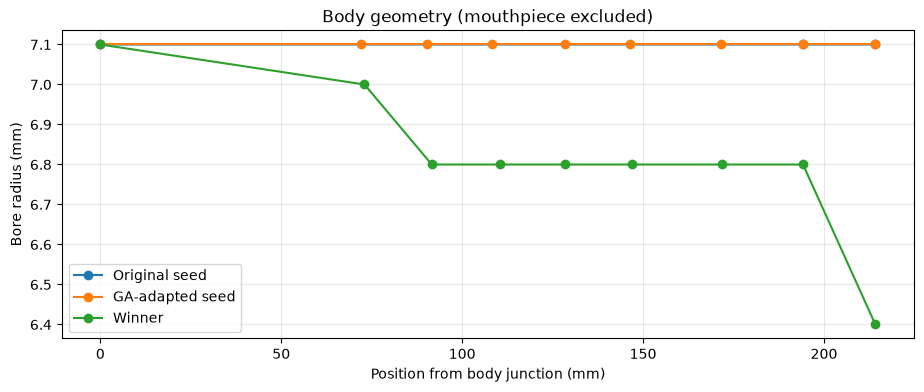

In [3]:
points = np.asarray(winner_bore.segments)
display(pd.DataFrame(points * 1000, columns=['Body position (mm)', 'Radius (mm)']))
dna = GeometryDNA.from_vector(vectors[WINNER_INDEX])
hole_table = pd.DataFrame([{'Hole': hole.label, 'Body position (mm)': hole.position_m * 1000, 'Distance from end (mm)': (winner_bore.length_m - hole.position_m) * 1000, 'Bore opening (mm)': 2 * hole.radius_in_m * 1000, 'Finger opening (mm)': 2 * hole.radius_out_m * 1000, 'Chimney (mm)': hole.chimney_height_m * 1000, 'Bevel (deg)': hole.bevel_deg, 'Bevel side': hole.bevel_side, 'Local bore radius (mm)': radius * 1000, 'Local outer diameter (mm)': 2 * (radius + hole.chimney_height_m) * 1000} for hole, radius in zip(winner_layout.holes, dna.bore_radii_at_holes_m)])
display(hole_table)
gaps = np.diff(winner_layout.positions_m)
display(pd.DataFrame({'Pair': ['L1-L2', 'L2-L3', 'L3-R1', 'R1-R2', 'R2-R3'], 'Center spacing (mm)': gaps * 1000, 'GA minimum (mm)': (np.asarray(MIN_ADJACENT_HOLE_SPACINGS_M) + 0.0001) * 1000}))
vector = vectors[WINNER_INDEX]
dimensions = dna.dimensional_values
checks = {'Genome on 0.1 mm grid': bool(np.allclose(dimensions / GEOMETRY_RESOLUTION_M, np.round(dimensions / GEOMETRY_RESOLUTION_M), atol=1e-8, rtol=0)), 'Body never widens': bool(np.all(np.diff(points[:, 1]) <= 1e-12)), 'Repair leaves genome unchanged': bool(np.allclose(vector, optimizer.codec.repair(vector), atol=1e-12, rtol=0)), 'Bottom clearance >= 30.1 mm': bool(winner_bore.length_m - winner_layout.positions_m[-1] >= 0.0301 - 1e-12)}
if config.independent_hole_geometry:
    checks.update({
        'Minimum wall': all(h.chimney_height_m >= config.minimum_wall_m - 1e-12 for h in winner_layout.holes),
        'Maximum body exterior': bool(hole_table['Local outer diameter (mm)'].max() <= config.max_outer_diameter_m * 1000 + 1e-9 and points[:, 1].max() + config.minimum_wall_m <= config.max_outer_diameter_m / 2 + 1e-12),
        'Inner openings fit bore': all(h.radius_in_m <= r + 1e-12 for h, r in zip(winner_layout.holes, dna.bore_radii_at_holes_m)),
        'Bore-side conical holes': all(h.bevel_side == 'bore' and h.radius_in_m >= h.radius_out_m for h in winner_layout.holes) if config.optimize_bevel else True,
    })
display(pd.Series(checks, name='Pass'))
winner_layout.validate(winner_bore.length_m)
if not all(checks.values()):
    raise ValueError('The winner failed a geometry check.')
if mouthpiece is not None:
    print(f'Mouthpiece: {mouthpiece.name}; saved segment endpoint {mouthpiece.segments[-1][0] * 1000:.3f} mm; acoustic offset {mouthpiece.l_mouth * 1000:.3f} mm')
    print('These mouthpiece quantities need not equal a physical core length. The combined profile below shows the actual simulation coordinates.')
    combined = WhistleGeometryFactory(temperature=context['temperature']).build_tapered_bore(mouthpiece, winner_bore)
    display(pd.DataFrame(np.asarray(combined) * 1000, columns=['Combined model position (mm)', 'Radius (mm)']))
fig, ax = plt.subplots(figsize=(11, 4))
for name, bore in [('Original seed', seed_bore), ('GA-adapted seed', adapted_bore), ('Winner', winner_bore)]:
    p = np.asarray(bore.segments) * 1000
    ax.plot(p[:, 0], p[:, 1], marker='o', label=name)
ax.set(xlabel='Position from body junction (mm)', ylabel='Bore radius (mm)', title='Body geometry (mouthpiece excluded)')
ax.grid(alpha=0.3)
ax.legend()
plt.show()

## Independent dense acoustic review

Use four times as many frequency intervals as the GA's 1201-point sweeps. The nearest interior |Y| peak to the target is selected, using the existing half-power Q routine (at least eight intervals per bandwidth). Missing or unresolved peaks remain explicit. No geometry repair is applied to the original seed in this comparison.

Roots use absolute errors; other notes use errors relative to their register's actual root. Pitch cost is 60% lower / 40% upper weighted mean squared error (root weight 10, others 1). A single register receives 100%. Missing resonance error is 1200 cents. Combined cost subtracts the saved Q reward weight times the register-weighted mean of Q/(Q+scale), with equal note weights per register. Missing/unresolved Q earns zero reward. Historical revisions default to zero Q weight. Compare component convergence, not only combined costs.

In [4]:
targets = generate_key_frequencies(key, '12-TET')
spectra = {}

def measure_design(name, bore, layout):
    acoustic = WhistleGeometryFactory(temperature=context['temperature']).create_tapered_instrument(mouthpiece, bore) if mouthpiece is not None else bore
    model = OpenWInDToneholeModel(acoustic, layout, context['temperature'], hole_position_offset_m=mouthpiece.l_mouth if mouthpiece is not None else 0.0)
    required = list(notes)
    for note in notes:
        root = 'Octave_Degree_1' if note in SECOND_REGISTER_FINGERINGS else 'Degree_1'
        if root not in required:
            required.append(root)
    rows = []
    for note in required:
        fingering = SECOND_REGISTER_FINGERINGS.get(note, note)
        upper = note in SECOND_REGISTER_FINGERINGS
        target = 2 * tuning.get_target_frequency(fingering, targets[fingering]) if upper and note != 'Octave_Degree_1' else tuning.get_target_frequency(note, targets[note])
        response = model.response(fingering, target, f_min=(0.8 if upper else 0.75) * target, f_max=(1.2 if upper else 1.25) * target, n_points=DENSE_POINTS)
        peaks = resonance_peak_rows(response.frequencies_hz, response.impedance, 'Y')
        peak = min(peaks, key=lambda p: abs(p['Peak (Hz)'] - target)) if peaks else None
        frequency = peak['Peak (Hz)'] if peak is not None else np.nan
        error = 1200 * np.log2(frequency / target) if peak is not None else 1200.0
        rows.append({'Note': note, 'Target (Hz)': target, 'Peak (Hz)': frequency, 'Absolute error (cents)': error, 'Q': peak['Q'] if peak is not None else np.nan, 'Bandwidth (Hz)': peak['Bandwidth (Hz)'] if peak is not None else np.nan, 'Status': peak['Status'] if peak is not None else 'No interior peak'})
        spectra[(name, note)] = response
    table = pd.DataFrame(rows).set_index('Note')
    for note in required:
        root = 'Octave_Degree_1' if note in SECOND_REGISTER_FINGERINGS else 'Degree_1'
        missing = not np.isfinite(table.loc[note, 'Peak (Hz)']) or not np.isfinite(table.loc[root, 'Peak (Hz)'])
        error = 1200.0 if missing else table.loc[note, 'Absolute error (cents)'] - (0 if note == root else table.loc[root, 'Absolute error (cents)'])
        table.loc[note, 'Scoring error (cents)'] = error
    contributions = normalized_pitch_costs(table.loc[list(notes), 'Scoring error (cents)'].to_dict())
    table['Pitch cost'] = pd.Series(contributions)
    q_factors = {note: None if pd.isna(table.loc[note, 'Q']) else float(table.loc[note, 'Q']) for note in notes}
    table['Q reward'] = pd.Series(normalized_q_rewards(q_factors, weight=config.q_reward_weight, scale=config.q_reward_scale))
    table['Total cost'] = table['Pitch cost'] - table['Q reward']
    return table.loc[list(notes)]

measurements = {name: measure_design(name, bore, layout) for name, bore, layout in [('Original seed', seed_bore, seed_layout), ('GA-adapted seed', adapted_bore, adapted_layout), ('Winner', winner_bore, winner_layout)]}
summary = []
for name, table in measurements.items():
    for register, mask in [('Lower', ~table.index.str.startswith('Octave_')), ('Upper', table.index.str.startswith('Octave_'))]:
        subset = table.loc[mask]
        if subset.empty:
            continue
        summary.append({'Design': name, 'Register': register, 'Absolute RMS (cents)': np.sqrt(subset['Absolute error (cents)'].pow(2).mean()), 'Worst absolute (cents)': subset['Absolute error (cents)'].abs().max(), 'Minimum Q': subset['Q'].min(), 'Unresolved Q': int(subset['Q'].isna().sum()), 'Pitch cost': subset['Pitch cost'].sum(), 'Q reward': subset['Q reward'].sum(), 'Cost': subset['Total cost'].sum()})
display(pd.DataFrame(summary))
display(measurements['Winner'])
display(measurements['Winner'][['Pitch cost', 'Q reward', 'Total cost']].sum().rename('Winner cost breakdown'))
dense = measurements['Winner']
ga_errors = pd.Series(score.errors)
ga_q = pd.Series(score.q_factors, dtype=float)
print(f'GA cost {score.cost:.6f}; dense cost {dense["Total cost"].sum():.6f}')
print(f'Maximum absolute pitch difference from GA: {(dense["Absolute error (cents)"] - ga_errors).abs().max():.4f} cents')
print(f'Maximum resolved Q difference from GA: {(dense["Q"] - ga_q).abs().max():.4f}')
print('Inspect status entries and grid convergence before accepting Q or a near-tied ranking.')

,Design,Register,Absolute RMS (cents),Worst absolute (cents),Minimum Q,Unresolved Q,Pitch cost,Q reward,Cost
0,Original seed,Lower,2.111651,5.728771,50.152406,0,1.222387,0.355176,0.867211
1,Original seed,Upper,21.504259,43.188212,55.083549,0,459.585841,0.251744,459.334096
2,GA-adapted seed,Lower,42.815827,74.354368,50.550901,0,328.688880,0.359722,328.329158
3,GA-adapted seed,Upper,51.084195,56.579337,67.299824,0,404.533788,0.257462,404.276326
4,Winner,Lower,24.651227,44.898709,49.502480,0,118.730312,0.357592,118.372720
5,Winner,Upper,44.152747,63.191663,66.252704,0,277.010773,0.258130,276.752643


,Target (Hz),Peak (Hz),Absolute error (cents),Q,Bandwidth (Hz),Status,Scoring error (cents),Pitch cost,Q reward,Total cost
Note,,,,,,,,,,
Degree_1,587.330000,590.067757,8.051157,49.502480,11.919964,OK,8.051157,22.878045,0.041481,22.836564
Degree_2,660.017677,671.458066,29.751167,53.915313,12.453940,OK,21.700010,16.619662,0.043056,16.576606
Degree_3,736.577842,747.234469,24.867610,56.750012,13.167124,OK,16.816454,9.980933,0.043992,9.936941
Degree_4,783.991492,798.866812,32.540399,58.618386,13.628264,OK,24.489242,21.166692,0.044580,21.122113
Degree_5,880.000695,884.798531,9.413191,61.240542,14.447921,OK,1.362034,0.065475,0.045368,0.020108
Degree_6,983.213459,987.073986,6.784274,63.874751,15.453273,OK,-1.266883,0.056647,0.046119,0.010528
Fork_Minor7,1042.882463,1070.282882,44.898709,63.914356,16.745579,OK,36.847552,47.920308,0.046130,47.874178
Degree_7,1105.533878,1111.391812,9.149136,66.631854,16.679587,OK,1.097980,0.042549,0.046866,-0.004317
Octave_Degree_1,1174.660000,1194.629484,29.183998,66.252704,18.031407,OK,29.183998,212.926440,0.035631,212.890809


Pitch cost    395.741085
Q reward        0.615722
Total cost    395.125363
Name: Winner cost breakdown, dtype: float64

GA cost 395.132240; dense cost 395.125363
Maximum absolute pitch difference from GA: 0.0006 cents
Maximum resolved Q difference from GA: 0.0099
Inspect status entries and grid convergence before accepting Q or a near-tied ranking.


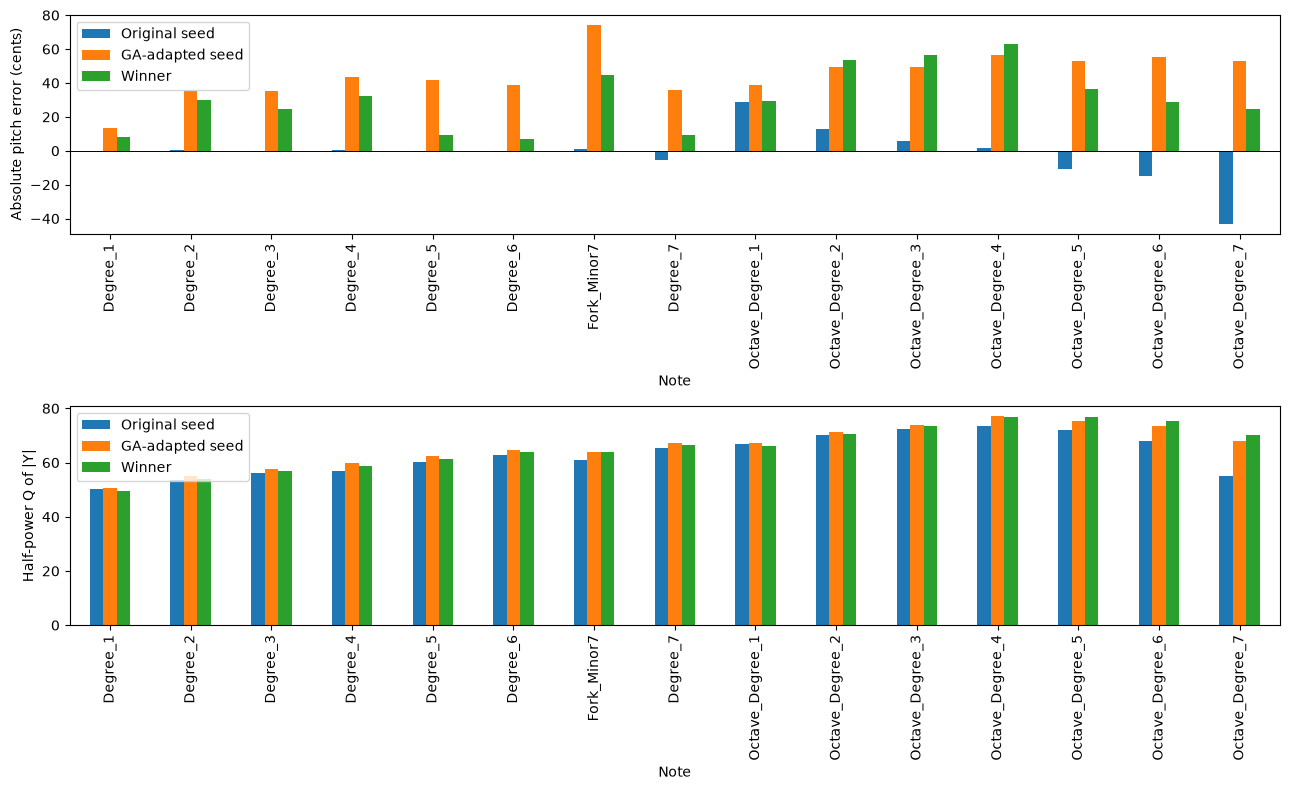

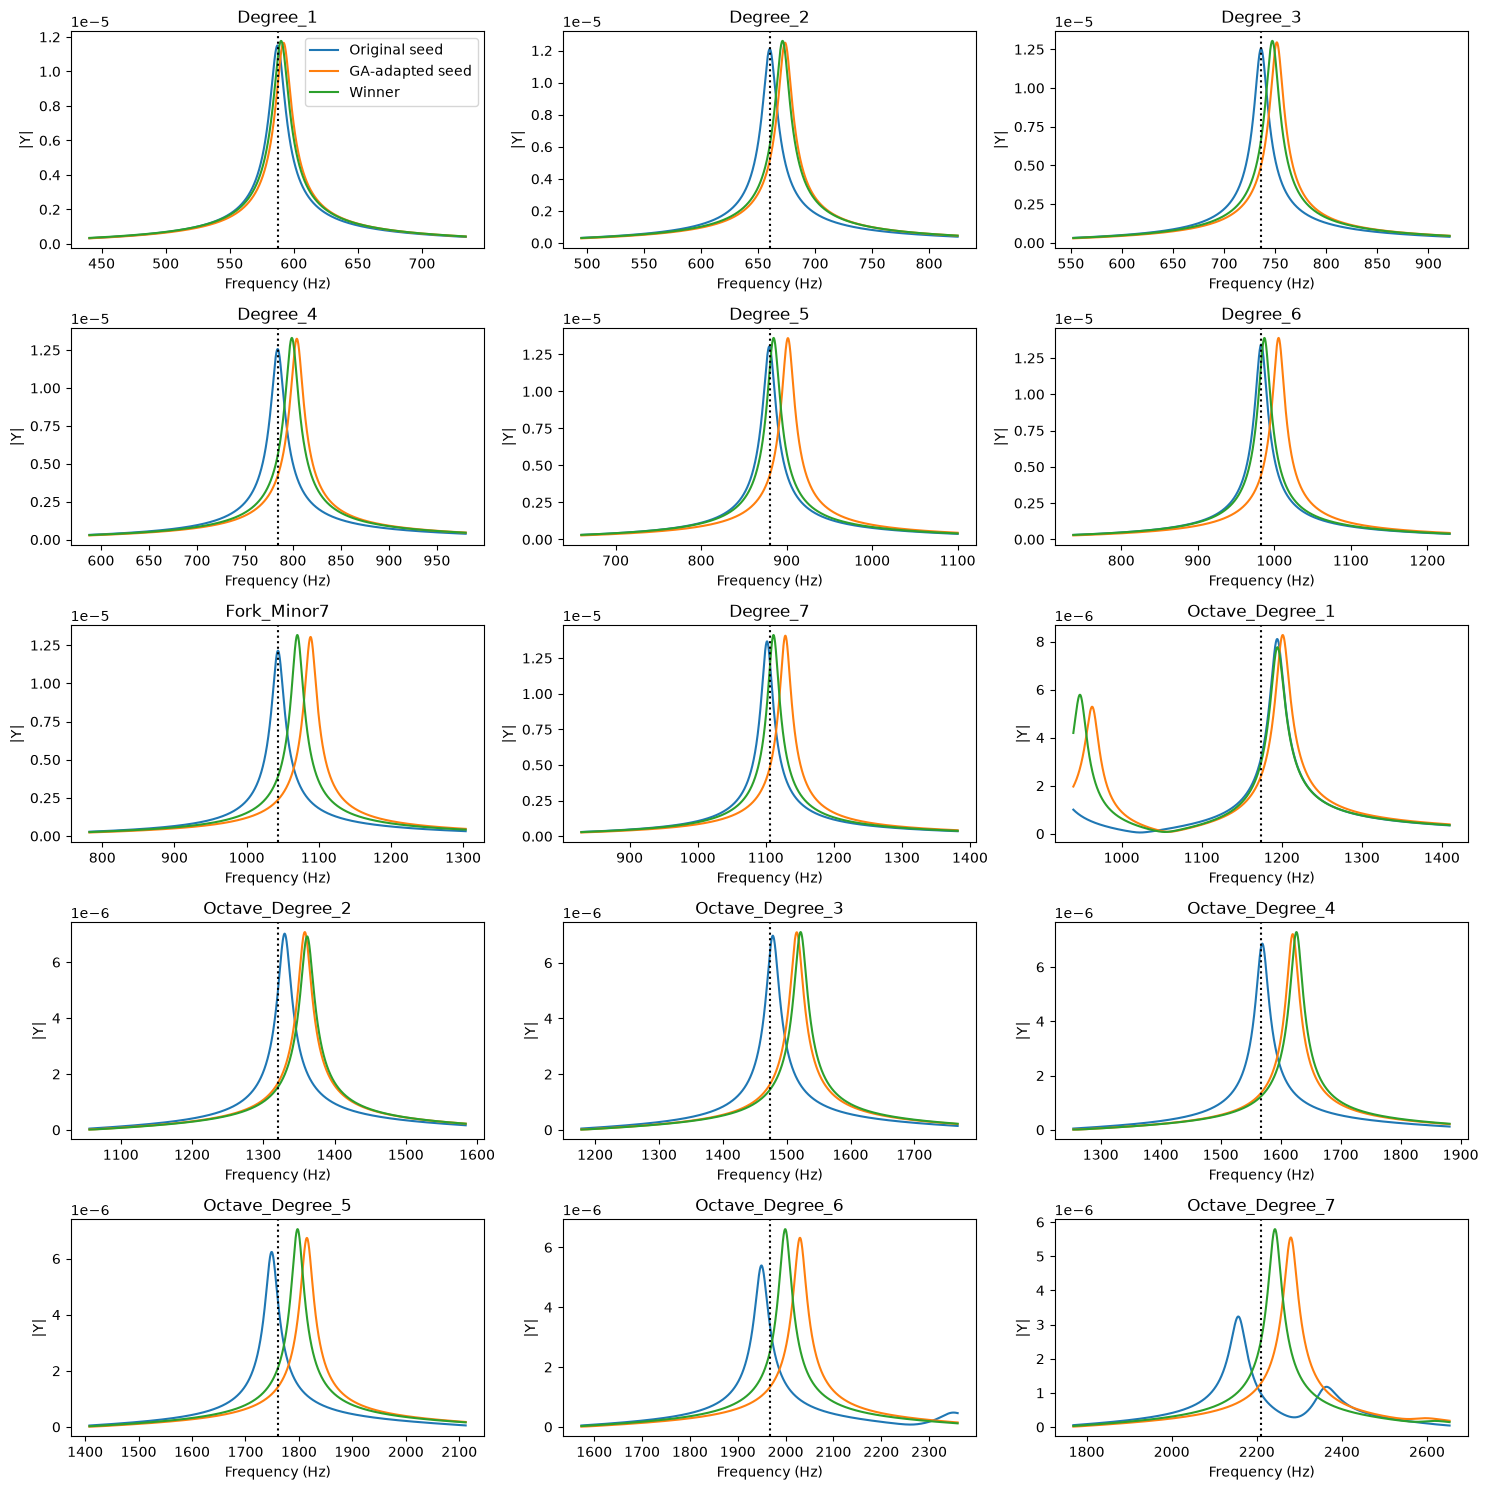

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(13, 8))
pd.DataFrame({name: table['Absolute error (cents)'] for name, table in measurements.items()}).plot.bar(ax=axes[0])
axes[0].axhline(0, color='black', linewidth=0.7)
axes[0].set_ylabel('Absolute pitch error (cents)')
pd.DataFrame({name: table['Q'] for name, table in measurements.items()}).plot.bar(ax=axes[1])
axes[1].set_ylabel('Half-power Q of |Y|')
axes[1].legend()
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(int(np.ceil(len(notes) / 3)), 3, figsize=(15, 3 * int(np.ceil(len(notes) / 3))))
for ax, note in zip(axes.flat, notes):
    for name in measurements:
        response = spectra[(name, note)]
        ax.plot(response.frequencies_hz, response.admittance, label=name)
    ax.axvline(dense.loc[note, 'Target (Hz)'], color='black', linestyle=':')
    ax.set(title=note, xlabel='Frequency (Hz)', ylabel='|Y|')
for ax in list(axes.flat)[len(notes):]:
    ax.set_visible(False)
axes.flat[0].legend()
fig.tight_layout()
plt.show()

## Is the result reasonable?

- A lower combined cost can sacrifice lower-register accuracy to improve the upper register. Examine both absolute pitch and relative intervals, not cost alone.
- When enabled, bounded Q rewards trade small pitch differences for higher resolved Q. Unresolved Q earns no reward. High passive Q is not proof of good response, stability, volume, or playability.
- Roots have 10x individual weight, not absolute priority over all remaining terms. There is no hard 0.1-cent acceptance gate in this scoring mode.
- Check whether the optimum is near hole-size, spacing, endhole or bore-radius bounds. The shrinking radius limits compound along the body. A modeled taper may be difficult to manufacture.
- The original seed is continuous; the GA-adapted seed is quantized and constrained. Their costs need not equal Stage 2's cost or each other.
- The saved mouthpiece has both segment coordinates and an acoustic offset. Inspect the combined model table and verify how it relates to the real instrument. This notebook does not alter that calibration or guarantee that acoustic length equals physical core length.
- These results are a plausible model-based design candidate, not a validated instrument. Recheck finer frequency grids, geometry/manufacturing tolerances and real playing measurements before drilling or fabrication.